In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/hamasali/notebooka8a82ea837/__huggingface_repos__.json
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/__notebook__.ipynb
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/__output__.json
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/__results__.html
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/custom.css
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/.gitignore
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/README.md
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/requirements.txt
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/.git/FETCH_HEAD
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/.git/HEAD
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/.git/ORIG_HEAD
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/.git/config
/kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-c

In [2]:
# Collect Stage 2 results from the training run's output (attached as Input),
# print the training + validation tables, and make ONE small zip to download.
import glob, json, os, re, shutil

# Where Kaggle mounted the training run's output
SRC = glob.glob("/kaggle/input/**/hlt-grpo-countdown", recursive=True)[0]
OUT = "/kaggle/working/stage2_results"
os.makedirs(f"{OUT}/results/stage2", exist_ok=True)
print("Source:", SRC)

# 1. Small result files -> results/stage2
for f in glob.glob(f"{SRC}/results/stage2/*.json") + \
         [f"{SRC}/checkpoints/stage2/log_history.json", f"{SRC}/checkpoints/stage2/run_info.json"]:
    shutil.copy(f, f"{OUT}/results/stage2/")

# 2. Training table (sampled answers, every 5 steps)
info = json.load(open(f"{OUT}/results/stage2/run_info.json"))
print(f"\nTRAINING: {info['steps_done']} steps | {info['seconds_per_step']} s/step | {info['train_time_s']/3600:.2f} h")
print(f"{'step':>5} | {'correct':>7} | {'format':>6} | {'no_sig':>6} | {'length':>6} | {'clipped':>7}")
for r in json.load(open(f"{OUT}/results/stage2/log_history.json")):
    if "reward" in r:
        print(f"{r['step']:>5} | {100*r['rewards/correctness_reward/mean']:6.1f}% | "
              f"{1000*r['rewards/format_reward_prefill/mean']:5.1f}% | {r['frac_reward_zero_std']:6.2f} | "
              f"{r['completions/mean_length']:6.1f} | {100*r['completions/clipped_ratio']:6.1f}%")

# 3. Validation table (greedy, one row per checkpoint)
files = sorted(glob.glob(f"{OUT}/results/stage2/val_step*_summary.json"),
               key=lambda f: int(re.search(r"val_step(\d+)_", f).group(1)))
rows = [(int(re.search(r"val_step(\d+)_", f).group(1)), json.load(open(f))) for f in files]
print(f"\nVALIDATION\n{'ckpt':>5} | {'2-num':>6} | {'3-num':>6} | {'all':>6} | {'length':>6} | {'clipped':>7}")
for step, s in rows:
    print(f"{step:>5} | {s['2_numbers']['accuracy']:6.1f} | {s['3_numbers']['accuracy']:6.1f} | "
          f"{s['all']['accuracy']:6.1f} | {s['all']['mean_tokens']:6.1f} | {s['all']['clipped_rate']:6.1f}%")

# 4. Best checkpoint = highest 3-number accuracy (ties -> overall); copy only its adapter files
best_step, best = max(rows, key=lambda r: (r[1]["3_numbers"]["accuracy"], r[1]["all"]["accuracy"]))
json.dump({"best_checkpoint": f"checkpoints/stage2/checkpoint-{best_step}", "best_step": best_step},
          open(f"{OUT}/results/stage2/best.json", "w"))
os.makedirs(f"{OUT}/checkpoints/stage2/best", exist_ok=True)
for f in glob.glob(f"{SRC}/checkpoints/stage2/checkpoint-{best_step}/adapter_*"):
    shutil.copy(f, f"{OUT}/checkpoints/stage2/best/")
print(f"\nBEST: checkpoint-{best_step} -> 2-num {best['2_numbers']['accuracy']}% | 3-num {best['3_numbers']['accuracy']}%")

# 5. One zip (~75 MB)
shutil.make_archive("/kaggle/working/stage2_results", "zip", OUT)
print("Zip:", round(os.path.getsize("/kaggle/working/stage2_results.zip") / 1e6, 1), "MB")

Source: /kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown

TRAINING: 400 steps | 24.45 s/step | 2.72 h
 step | correct | format | no_sig | length | clipped
    5 |   18.8% |  99.4% |   0.70 |   45.6 |    0.6%
   10 |   30.0% |  98.1% |   0.65 |   46.8 |    1.2%
   15 |   33.1% | 100.0% |   0.60 |   47.9 |    0.0%
   20 |   33.8% |  99.4% |   0.78 |   47.8 |    0.6%
   25 |   37.5% | 100.0% |   0.60 |   46.7 |    0.0%
   30 |   35.6% |  96.9% |   0.42 |   55.8 |    2.5%
   35 |   25.0% |  98.1% |   0.57 |   59.1 |    1.2%
   40 |   31.2% |  98.7% |   0.68 |   57.0 |    1.2%
   45 |   33.8% |  99.4% |   0.55 |   56.8 |    0.6%
   50 |   28.1% |  96.2% |   0.62 |   57.7 |    1.9%
   55 |   40.6% |  96.9% |   0.55 |   61.0 |    2.5%
   60 |   41.2% |  97.5% |   0.60 |   54.4 |    2.5%
   65 |   38.8% |  97.5% |   0.60 |   52.4 |    1.9%
   70 |   25.0% |  97.5% |   0.68 |   55.0 |    2.5%
   75 |   20.6% |  97.5% |   0.82 |   48.8 |    1.9%
   80 |   30.0% |  98.8% |  

# HLT Project — Final evaluation on the TEST set (Group 2)
**Model:** Qwen2.5-1.5B-Instruct + GRPO LoRA, Stage 2 **checkpoint-375** (best on val: 2-num 98%, 3-num 60%)
**Test sets:** `test.jsonl` (500 × 2-number + 500 × 3-number) and `test_ood.jsonl` (500 × 4-number, never trained on)
**Compared with:** zero-shot and CoT baselines (same prompt, verifier, greedy decoding, 256 tokens).
The test set was never used for training or checkpoint choice, so these are the honest final numbers.

In [2]:
# 1. Code (main), libraries, data
import os, glob, json
REPO, GITHUB_USER = "hlt-grpo-countdown", "hamasli"     # <-- change this
if not os.path.exists(f"/kaggle/working/{REPO}"):
    !git clone https://github.com/{GITHUB_USER}/{REPO}.git /kaggle/working/{REPO}
%cd /kaggle/working/{REPO}
!git checkout main && git pull
!pip uninstall -y -q torchao
!pip install -q trl peft
if not os.path.exists("data/test.jsonl"):
    !python -m src.data.generate
!wc -l data/test.jsonl data/test_ood.jsonl                  # 1000 + 500

Cloning into '/kaggle/working/hlt-grpo-countdown'...
remote: Enumerating objects: 355, done.
remote: Counting objects: 100% (355/355), done.
remote: Compressing objects: 100% (217/217), done.
remote: Total 355 (delta 189), reused 288 (delta 126), pack-reused 0 (from 0)
Receiving objects: 100% (355/355), 4.34 MiB | 15.48 MiB/s, done.
Resolving deltas: 100% (189/189), done.
/kaggle/working/hlt-grpo-countdown
Already on 'main'
Your branch is up to date with 'origin/main'.
Already up to date.
  1000 data/test.jsonl
   500 data/test_ood.jsonl
  1500 total


In [3]:
# 2. Best Stage 2 checkpoint, from the attached training run output.
BEST_STEP = 375
hits = glob.glob(f"/kaggle/input/**/checkpoints/stage2/checkpoint-{BEST_STEP}", recursive=True)
assert hits, "checkpoint not found -> Add Input: notebook notebooka8a82ea837"
ADAPTER = hits[0]
print("Adapter:", ADAPTER, "|", [f for f in os.listdir(ADAPTER) if f.startswith("adapter")])

Adapter: /kaggle/input/notebooks/hamasali/notebooka8a82ea837/hlt-grpo-countdown/checkpoints/stage2/checkpoint-375 | ['adapter_config.json', 'adapter_model.safetensors']


## 3. Evaluate GRPO on test + test_ood (greedy)
Same `evaluate.py` as the baselines → identical prompt, decoding, token limit and verifier.
Outputs: `results/Qwen2.5-1.5B-Instruct_grpo_summary.json` and `..._grpo_test_ood_summary.json` (+ the per-puzzle outputs for error analysis).

In [4]:
# 3. Test (2+3 numbers) and OOD (4 numbers)
!python -m src.eval.evaluate --model Qwen/Qwen2.5-1.5B-Instruct --method grpo --adapter {ADAPTER} --data data/test.jsonl
!python -m src.eval.evaluate --model Qwen/Qwen2.5-1.5B-Instruct --method grpo --adapter {ADAPTER} --data data/test_ood.jsonl

config.json: 100%|█████████████████████████████| 660/660 [00:00<00:00, 3.32MB/s]
tokenizer_config.json: 100%|███████████████| 7.30k/7.30k [00:00<00:00, 30.8MB/s]
vocab.json: 100%|███████████████████████████| 2.78M/2.78M [00:00<00:00, 109MB/s]
merges.txt: 100%|███████████████████████████| 1.67M/1.67M [00:00<00:00, 123MB/s]
tokenizer.json: 100%|███████████████████████| 7.03M/7.03M [00:00<00:00, 150MB/s]

model.safetensors: downloading bytes:                       |  0.00B            
model.safetensors: downloading bytes: ▍                     | 60.5MB, 3.50MB/s  
model.safetensors: downloading bytes: ▉                     |  127MB, 9.47MB/s  
model.safetensors: downloading bytes: █▏                    |  161MB, 11.7MB/s  
model.safetensors: downloading bytes: █▎                    |  186MB, 14.7MB/s  
model.safetensors: downloading bytes: ████▎                 |  611MB, 48.3MB/s  
model.safetensors: downloading bytes: ████▋                 |  663MB, 52.6MB/s  
model.safetensors: download

In [5]:
# 4. Final comparison: zero-shot vs CoT vs GRPO (1.5B), on test + OOD.
#    Baseline summaries come from results/ on GitHub; GRPO from step 3.
M = "Qwen2.5-1.5B-Instruct"
def load(method, ood=False):
    return json.load(open(f"results/{M}_{method}{'_test_ood' if ood else ''}_summary.json"))

print(f"{'method':<10} | {'2-num':>6} | {'3-num':>6} | {'4-num OOD':>9} | {'tokens 2/3/4':>15} | {'clipped 2/3/4':>15}")
for method in ["zero_shot", "cot", "grpo"]:
    t, o = load(method), load(method, ood=True)
    a2, a3, a4 = t["2_numbers"], t["3_numbers"], o["4_numbers"]
    print(f"{method:<10} | {a2['accuracy']:6.1f} | {a3['accuracy']:6.1f} | {a4['accuracy']:9.1f} | "
          f"{a2['mean_tokens']:4.0f}/{a3['mean_tokens']:4.0f}/{a4['mean_tokens']:4.0f} | "
          f"{a2['clipped_rate']:4.1f}/{a3['clipped_rate']:4.1f}/{a4['clipped_rate']:4.1f}")

method     |  2-num |  3-num | 4-num OOD |    tokens 2/3/4 |   clipped 2/3/4
zero_shot  |    0.2 |    0.0 |       0.0 |   17/  19/  20 |  0.0/ 0.0/ 0.0
cot        |   26.4 |    3.0 |       0.4 |   43/  76/  81 |  0.4/ 4.6/ 2.6
grpo       |   95.6 |   64.0 |      12.8 |   29/  52/  88 |  0.8/ 2.2/ 8.4


In [6]:
# 5. Error categories for all runs (now including GRPO), then zip the results to download.
!python -m src.eval.error_analysis
!zip -qr /kaggle/working/final_eval.zip results/*grpo* results/error_analysis.json
!ls -lh /kaggle/working/final_eval.zip

run                               level              correct      no_answer        invalid  wrong_numbers    wrong_value
------------------------------------------------------------------------------------------------------------------------
Qwen2.5-0.5B-Instruct_cot         2_numbers             7.6%          68.6%           1.4%          19.8%           2.6%
Qwen2.5-0.5B-Instruct_cot         3_numbers             1.6%          55.8%           0.0%          26.2%          16.4%
Qwen2.5-0.5B-Instruct_cot         all                   4.6%          62.2%           0.7%          23.0%           9.5%
Qwen2.5-0.5B-Instruct_cot_test_ood4_numbers             0.2%          35.0%           0.6%          15.2%          49.0%
Qwen2.5-0.5B-Instruct_cot_test_oodall                   0.2%          35.0%           0.6%          15.2%          49.0%
Qwen2.5-0.5B-Instruct_zero_shot   2_numbers             0.0%           0.0%           0.0%         100.0%           0.0%
Qwen2.5-0.5B-Instruct_zero_shot 

## Error analysis (test, 1.5B)
| Method | correct | no answer | invalid | wrong numbers | wrong value |
|---|---|---|---|---|---|
| CoT (2+3 numbers) | 14.7 | 2.6 | 5.9 | 38.0 | 38.8 |
| GRPO (2+3 numbers) | 79.8 | 0.7 | 0.0 | 4.3 | 15.2 |
| GRPO (4 numbers, OOD) | 12.8 | 4.2 | 0.0 | 58.0 | 25.0 |

1. **GRPO learned the rules of the task.** Invalid answers dropped to 0% and rule violations from 38% to 4.3%;
   CoT's main mistake was inventing numbers (93% of its rule violations).
2. **Remaining errors are near misses.** Wrong-value answers are on average 21.6 away from the target
   (CoT: 1,269): the model understands the task but does not always find the exact combination.
3. **Size overfitting on OOD.** On 4-number puzzles, 58% of answers break the rules, and 99% of those
   leave one number unused: after training only on 3 numbers, the model tends to use exactly 3 numbers.
4. **Loops cause the "no answer" cases.** The model sometimes repeats the same adjustments
   ("add 8 … subtract 8 again …") until it hits the 256-token limit.

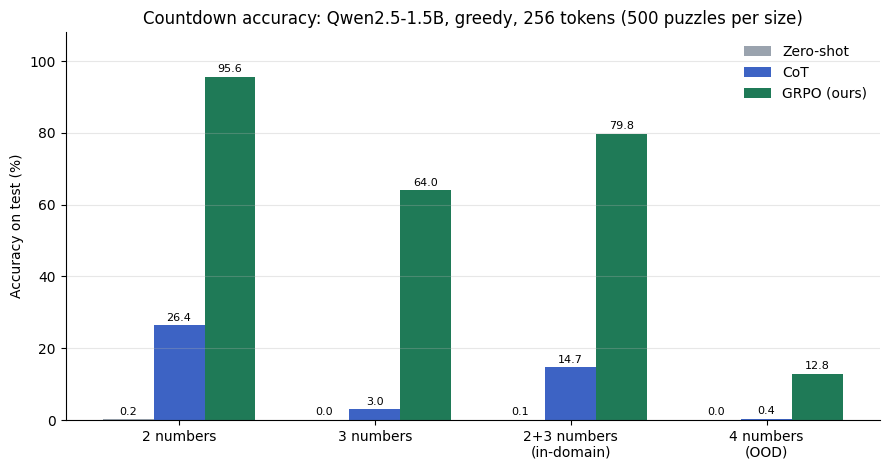

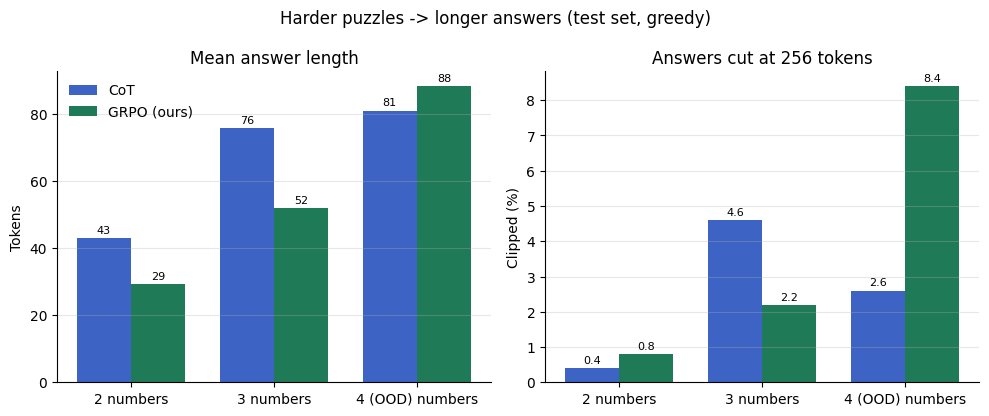

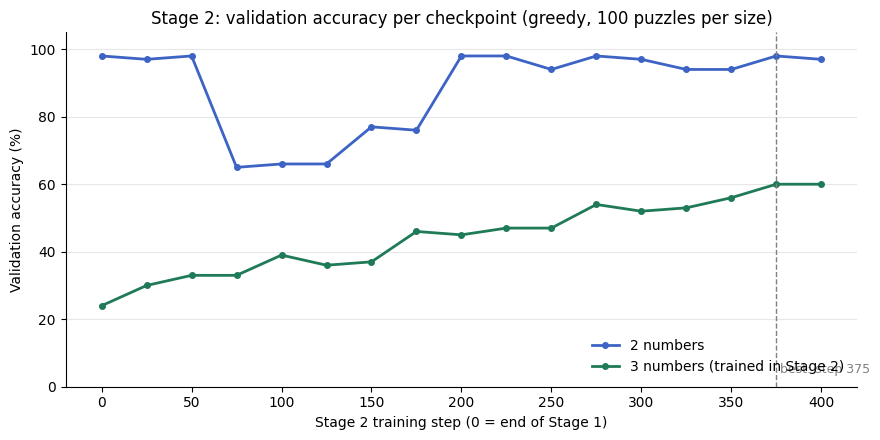

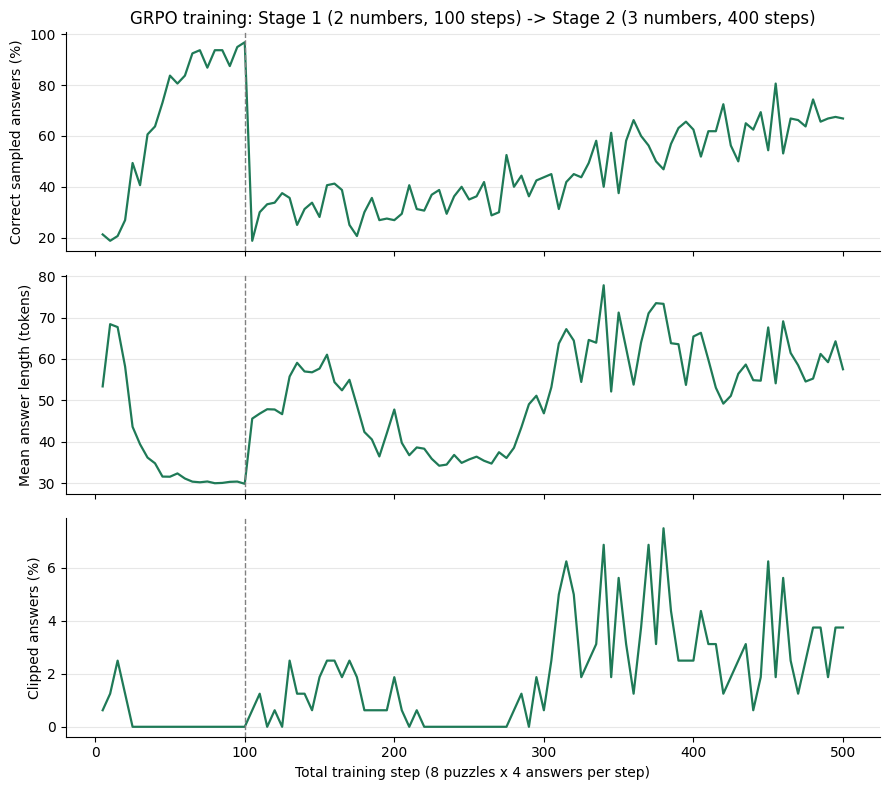

Saved: ['fig1_test_accuracy.png', 'fig3_stage2_val.png', 'fig2_length_clipping.png', 'fig4_training_curves.png']


In [10]:
# All result figures in one cell -> shown here + saved in results/figures/
# Needs: test summaries (results/), Stage 1 files (results/stage1/), Stage 2 val + log files.
import glob, json, os, re
import matplotlib.pyplot as plt

M = "Qwen2.5-1.5B-Instruct"
OUT = "results/figures"; os.makedirs(OUT, exist_ok=True)
METHODS = ["zero_shot", "cot", "grpo"]
NAMES  = {"zero_shot": "Zero-shot", "cot": "CoT", "grpo": "GRPO (ours)"}
COLORS = {"zero_shot": "#9AA3AE", "cot": "#3D63C4", "grpo": "#1F7A57"}

def find(pattern):
    """First file matching the pattern in the repo, else in /kaggle/input."""
    hits = glob.glob(pattern, recursive=True) or glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    assert hits, f"not found: {pattern}"
    return hits

def load(method, ood=False):
    return json.load(open(find(f"results/{M}_{method}{'_test_ood' if ood else ''}_summary.json")[0]))

def style(ax):
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)

def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}", dpi=150); plt.show()

# ---------- Fig 1: test accuracy ----------
groups = [("2 numbers", False, "2_numbers"), ("3 numbers", False, "3_numbers"),
          ("2+3 numbers\n(in-domain)", False, "all"), ("4 numbers\n(OOD)", True, "4_numbers")]
fig, ax = plt.subplots(figsize=(9, 4.8)); w = 0.26
for i, m in enumerate(METHODS):
    vals = [load(m, ood)[k]["accuracy"] for _, ood, k in groups]
    bars = ax.bar([g + (i - 1) * w for g in range(len(groups))], vals, w, label=NAMES[m], color=COLORS[m])
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
ax.set_xticks(range(len(groups))); ax.set_xticklabels([g[0] for g in groups])
ax.set_ylabel("Accuracy on test (%)"); ax.set_ylim(0, 108); ax.legend(frameon=False); style(ax)
ax.set_title("Countdown accuracy: Qwen2.5-1.5B, greedy, 256 tokens (500 puzzles per size)")
save(fig, "fig1_test_accuracy.png")

# ---------- Fig 2: length + clipping (two panels, no double axis) ----------
sizes = [("2", False, "2_numbers"), ("3", False, "3_numbers"), ("4 (OOD)", True, "4_numbers")]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2)); w = 0.38
for i, m in enumerate(["cot", "grpo"]):
    xs = [s + (i - 0.5) * w for s in range(len(sizes))]
    a1.bar_label(a1.bar(xs, [load(m, o)[k]["mean_tokens"] for _, o, k in sizes], w, label=NAMES[m], color=COLORS[m]), fmt="%.0f", padding=2, fontsize=8)
    a2.bar_label(a2.bar(xs, [load(m, o)[k]["clipped_rate"] for _, o, k in sizes], w, label=NAMES[m], color=COLORS[m]), fmt="%.1f", padding=2, fontsize=8)
for ax, title, ylab in [(a1, "Mean answer length", "Tokens"), (a2, "Answers cut at 256 tokens", "Clipped (%)")]:
    ax.set_xticks(range(len(sizes))); ax.set_xticklabels([s[0] + " numbers" for s in sizes])
    ax.set_title(title); ax.set_ylabel(ylab); style(ax)
a1.legend(frameon=False); fig.suptitle("Harder puzzles -> longer answers (test set, greedy)")
save(fig, "fig2_length_clipping.png")

# ---------- Fig 3: Stage 2 val per checkpoint (best computed here, no best.json needed) ----------
files = find("results/stage2/val_step*_summary.json")
rows = sorted((int(re.search(r"val_step(\d+)_", f).group(1)), json.load(open(f))) for f in files)
best_step = max(rows, key=lambda r: (r[1]["3_numbers"]["accuracy"], r[1]["all"]["accuracy"]))[0]
s1 = json.load(open(find(f"results/stage1/{M}_grpo_val_summary.json")[0]))
steps = [0] + [s for s, _ in rows]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(steps, [s1["2_numbers"]["accuracy"]] + [r["2_numbers"]["accuracy"] for _, r in rows], marker="o", ms=4, lw=2, color=COLORS["cot"], label="2 numbers")
ax.plot(steps, [s1["3_numbers"]["accuracy"]] + [r["3_numbers"]["accuracy"] for _, r in rows], marker="o", ms=4, lw=2, color=COLORS["grpo"], label="3 numbers (trained in Stage 2)")
ax.axvline(best_step, color="gray", ls="--", lw=1); ax.text(best_step, 4, f" best: step {best_step}", color="gray", fontsize=9)
ax.set_xlabel("Stage 2 training step (0 = end of Stage 1)"); ax.set_ylabel("Validation accuracy (%)")
ax.set_ylim(0, 105); ax.legend(frameon=False, loc="lower right"); style(ax)
ax.set_title("Stage 2: validation accuracy per checkpoint (greedy, 100 puzzles per size)")
save(fig, "fig3_stage2_val.png")
os.makedirs("results/stage2", exist_ok=True)                           # folder may not exist in this notebook
json.dump({"best_checkpoint": f"checkpoints/stage2/checkpoint-{best_step}", "best_step": best_step},
          open("results/stage2/best.json", "w"))                       # create it now for later use

# ---------- Fig 4: training curves, Stage 1 -> Stage 2 ----------
logs = []
for stage, offset in [("stage1", 0), ("stage2", 100)]:
    path = (glob.glob(f"results/{stage}/log_history.json") or find(f"checkpoints/{stage}/log_history.json"))[0]
    logs += [(r["step"] + offset, r) for r in json.load(open(path)) if "reward" in r]
panels = [("Correct sampled answers (%)", lambda r: 100 * r["rewards/correctness_reward/mean"]),
          ("Mean answer length (tokens)", lambda r: r["completions/mean_length"]),
          ("Clipped answers (%)",         lambda r: 100 * r["completions/clipped_ratio"])]
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ax, (label, get) in zip(axes, panels):
    ax.plot([s for s, _ in logs], [get(r) for _, r in logs], color=COLORS["grpo"], lw=1.6)
    ax.axvline(100, color="gray", ls="--", lw=1); ax.set_ylabel(label); style(ax)
axes[0].set_title("GRPO training: Stage 1 (2 numbers, 100 steps) -> Stage 2 (3 numbers, 400 steps)")
axes[-1].set_xlabel("Total training step (8 puzzles x 4 answers per step)")
save(fig, "fig4_training_curves.png")
print("Saved:", os.listdir(OUT))

# Results — Reasoning with Verifiable Rewards (Group 2)

## Setup
- **Model:** Qwen2.5-1.5B-Instruct + LoRA (r = 16, α = 32, all linear layers, ~18.5M trainable params, 1.2%)
- **Training:** GRPO (DeepSeekMath loss, β = 0, ε = 0.2), G = 4 answers per puzzle, 8 puzzles per step, lr 1e-5,
  temperature 1.0, max 256 tokens, fp16 on one Kaggle T4
- **Reward:** rule-based verifier, 1.0 correct equation + 0.1 correct format (no reward model, no critic)
- **Curriculum:** Stage 1 = 2-number puzzles (100 steps, 24 min) → Stage 2 = 3-number puzzles (400 steps, 2.7 h),
  starting from the Stage 1 LoRA
- **Model selection:** best Stage 2 checkpoint on validation = **step 375**
- **Evaluation:** test set (500 puzzles per size) + 4-number OOD set (500 puzzles, never trained on),
  greedy decoding, 256 tokens, same prompt and verifier for every method

## 1. Main result — test accuracy (`results/figures/fig1_test_accuracy.png`)
| Method | 2 numbers | 3 numbers | 2+3 (in-domain) | 4 numbers (OOD) |
|---|---|---|---|---|
| Zero-shot | 0.2 | 0.0 | 0.1 | 0.0 |
| CoT | 26.4 | 3.0 | 14.7 | 0.4 |
| **GRPO (ours)** | **95.6** | **64.0** | **79.8** | **12.8** |
| Random equation, 4 tries (trick baseline) | 78.6 | 27.6 | – | 6.8 |

GRPO improves every puzzle size: 3-number accuracy goes from 3.0% to 64.0%, far above random search
(27.6% with 4 tries), so the model really solves the puzzles instead of guessing.

## 2. Training dynamics (`fig4_training_curves.png`, `fig3_stage2_val.png`)
- **Stage 1 (2 numbers):** training accuracy 20% → ~95% in ~60 steps; answers shrink from ~55 to ~30 tokens
  (the model learns to answer directly). Validation: 2 numbers 28% → 98%, and 3 numbers 4% → 24% without
  ever seeing a 3-number puzzle (transfer).
- **Stage 2 (3 numbers):** the drop at the start is caused by harder puzzles, not forgetting.
  Accuracy stays around 30–40% while answers are short (~35 tokens, steps 100–280); **from step ~290 the model
  starts writing longer reasoning (55–75 tokens) and accuracy rises to ~65%.** Validation 3-number accuracy
  grows steadily: 24% → 33% → 46% → 54% → 60% (steps 0 → 50 → 175 → 275 → 375).
- **Temporary forgetting:** 2-number validation accuracy dropped from 98% to 65–77% (steps 75–175),
  then recovered to 94–98% for the rest of training.
- **Not finished:** validation accuracy was still at its maximum at the last checkpoints (60% at 375 and 400),
  while 70–80% of groups gave no learning signal (all 4 answers equally right or wrong).

## 3. Answer length and clipping (`fig2_length_clipping.png`)
| | 2 numbers | 3 numbers | 4 numbers (OOD) |
|---|---|---|---|
| Tokens: CoT / GRPO | 43 / 29 | 76 / 52 | 81 / 88 |
| Clipped: CoT / GRPO | 0.4 / 0.8 % | 4.6 / 2.2 % | 2.6 / 8.4 % |

- **Adaptive reasoning:** GRPO answers grow with difficulty (29 → 52 → 88 tokens). The model spends more
  reasoning on harder puzzles without being told to; length is never rewarded directly.
- **Shorter and more accurate than CoT in-domain:** fewer tokens on 2 and 3 numbers, with much higher accuracy.
- **Clipping is low in-domain** (0.8% / 2.2%) and **rises on OOD** (8.4% = 42 of 500 answers). A clipped answer
  has no `<answer>`, so it always counts as wrong: part of the OOD error comes from the 256-token budget.
- **Why clipping stays under control:** a clipped answer gets reward 0, so in a group with a finished correct
  answer it gets a negative advantage; GRPO itself pushes the model to finish within the budget.

## 4. Error analysis (`results/error_analysis.json`)
| Method | correct | no answer | invalid | wrong numbers | wrong value |
|---|---|---|---|---|---|
| CoT (2+3 numbers) | 14.7 | 2.6 | 5.9 | 38.0 | 38.8 |
| GRPO (2+3 numbers) | 79.8 | 0.7 | 0.0 | 4.3 | 15.2 |
| GRPO (4 numbers, OOD) | 12.8 | 4.2 | 0.0 | 58.0 | 25.0 |

- **GRPO learned the rules:** invalid answers dropped to 0% and rule violations from 38% to 4.3%
  (CoT mostly invented numbers: 93% of its rule violations).
- **Remaining errors are near misses:** wrong-value answers are on average 21.6 from the target (CoT: 1,269).
- **Size overfitting on OOD:** 58% of 4-number answers break the rules, and 99% of those leave one number
  unused. After training only on 3 numbers, the model tends to use exactly 3 numbers.
- **"No answer" comes from loops:** e.g. "add 8 … subtract 8 again … add 8 …" until the 256-token limit.

## 5. Conclusions
1. **RL with a verifiable reward works without labelled reasoning:** only "right/wrong" feedback took
   3-number accuracy from 3.0% to 64.0% and taught the model the rules of the task.
2. **Curriculum learning transfers:** training on 2 numbers already improved 3 numbers (4% → 24%).
3. **Reasoning length emerges by itself:** accuracy on 3 numbers rose when the model started reasoning longer,
   and answer length scales with puzzle difficulty (29 → 52 → 88 tokens).
4. **Generalization is real but limited:** 4-number accuracy 0.4% → 12.8%, held back by the "use 3 numbers"
   habit and by the 256-token limit.

## 6. Limitations
- One run, one seed; validation uses 100 puzzles per size (about ±5 points).
- The 256-token budget caps OOD performance (8.4% clipped).
- Training one size at a time caused temporary forgetting (Stage 2) and size overfitting (OOD).
- The original GRPO loss averages per answer, which can favour long wrong answers (Dr. GRPO, Liu et al. 2025).

## 7. Next experiment
Train on a **mix of 2- and 3-number puzzles** in a single stage, to avoid the forgetting dip and keep
a learning signal from both sizes; compare with the 2 → 3 curriculum on the same test set.

## Files
| What | Where |
|---|---|
| Final model (LoRA adapter, Stage 2 step 375) | local `checkpoints/stage2/best/` + Kaggle Dataset `grpo-stage2-best` (not on GitHub) |
| Test / OOD summaries + per-puzzle outputs | `results/Qwen2.5-1.5B-Instruct_*` |
| Stage 1 / Stage 2 training logs + validation | `results/stage1/`, `results/stage2/` |
| Figures | `results/figures/` |
| Notebooks | `notebooks/` |

In [11]:
# Everything from this notebook: GRPO test/OOD results, error analysis, figures, best.json
!zip -qr /kaggle/working/final_all.zip results/*grpo* results/error_analysis.json results/figures results/stage2/best.json
!ls -lh /kaggle/working/final_all.zip

-rw-r--r-- 1 root root 414K Nov 16 16:07 /kaggle/working/final_all.zip
